# Fashion-MNIST Convolutional Classifier (M1 Series)

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 1 SIEC · 2023–2024 (inferred from neighboring numbered TP series; not explicitly in this source file)  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Recognize clothing types from grayscale images.

**Approach:** CNN on Fashion-MNIST.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


# TP 2 AI USING CNN

## Classification with ( Deep Learning Technics)
### GUERBOUZ MOHAMMED ALAA EDDINE

In [28]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

# Load the Fashion MNIST dataset
dataset = datasets.fashion_mnist.load_data()
(train_images, train_labels), (test_images, test_labels) = dataset


# Loading " MNIST DATASETS "
## Contains 60k Training samples  , 10k  Testing Samples
### it is in the Metadata of the tensorFlow Library and Exactly from keras

## Explore the Dataset

In [29]:
# Display dataset
dataset

((array([[[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         ...,
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]],
  
         [[0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0

The images in this dataset are 28 $\times$ 28 arrays, with pixel values in the range `[0, 255]`. The *labels* are an array of integers, in the range `[0, 9]`. These correspond to the *class* of clothing the image represents:

<table>
  <tr>
    <th>Label</th>
    <th>Class</th> 
  </tr>
  <tr>
    <td>0</td>
    <td>T-shirt/top</td> 
  </tr>
  <tr>
    <td>1</td>
    <td>Trouser</td> 
  </tr>
    <tr>
    <td>2</td>
    <td>Pullover</td> 
  </tr>
    <tr>
    <td>3</td>
    <td>Dress</td> 
  </tr>
    <tr>
    <td>4</td>
    <td>Coat</td> 
  </tr>
    <tr>
    <td>5</td>
    <td>Sandal</td> 
  </tr>
    <tr>
    <td>6</td>
    <td>Shirt</td> 
  </tr>
    <tr>
    <td>7</td>
    <td>Sneaker</td> 
  </tr>
    <tr>
    <td>8</td>
    <td>Bag</td> 
  </tr>
    <tr>
    <td>9</td>
    <td>Ankle boot</td> 
  </tr>
</table>

Each image is mapped to a single label. Since the *class names* are not included with the dataset, we create them here to use later when plotting the images:

In [30]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
               'Sandal',      'Shirt',   'Sneaker',  'Bag',   'Ankle boot']

## Build the Model and Train the model

In [5]:

# Normalize pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0

# Reshape images to have a single channel
train_images = np.expand_dims(train_images, axis=-1)
test_images = np.expand_dims(test_images, axis=-1)

# Define number of classes
num_classes = 10

# Define your CNN model
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

# Compile the model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Train the model
history = model.fit(train_images, train_labels, epochs=10, validation_split=0.2)


Epoch 1/10
1500/1500 [==============================] - 28s 17ms/step - loss: 0.5269 - accuracy: 0.8062 - val_loss: 0.3994 - val_accuracy: 0.8532
Epoch 2/10
1500/1500 [==============================] - 22s 15ms/step - loss: 0.3357 - accuracy: 0.8787 - val_loss: 0.3185 - val_accuracy: 0.8844
Epoch 3/10
1500/1500 [==============================] - 22s 14ms/step - loss: 0.2875 - accuracy: 0.8944 - val_loss: 0.2894 - val_accuracy: 0.8973
Epoch 4/10
1500/1500 [==============================] - 21s 14ms/step - loss: 0.2573 - accuracy: 0.9046 - val_loss: 0.2813 - val_accuracy: 0.8992
Epoch 5/10
1500/1500 [==============================] - 22s 15ms/step - loss: 0.2326 - accuracy: 0.9126 - val_loss: 0.3060 - val_accuracy: 0.8903
Epoch 6/10
1500/1500 [==============================] - 22s 15ms/step - loss: 0.2113 - accuracy: 0.9221 - val_loss: 0.2761 - val_accuracy: 0.9035
Epoch 7/10
1500/1500 [==============================] - 22s 15ms/step - loss: 0.1932 - accuracy: 0.9282 - val_loss: 0.2570 -

## Evaluate Loss and Accuracy on the Test Set

In [31]:
loss, accuracy = model.evaluate(test_images, test_labels)

print('\nLoss on the TEST Set: {:,.3f}'.format(loss))
print('Accuracy on the TEST Set: {:.3%}'.format(accuracy))

313/313 [==============================] - 1s 3ms/step - loss: 96.6416 - accuracy: 0.7953

Loss on the TEST Set: 96.642
Accuracy on the TEST Set: 79.530%


## Loss and Validation Plots

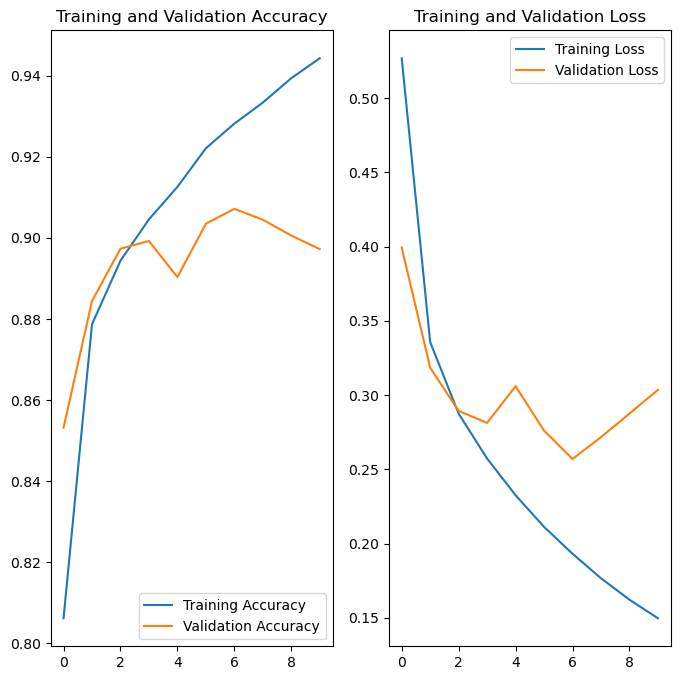

In [32]:
training_accuracy = history.history['accuracy']
validation_accuracy = history.history['val_accuracy']

training_loss = history.history['loss']
validation_loss = history.history['val_loss']

epochs_range=range(10)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, training_accuracy, label='Training Accuracy')
plt.plot(epochs_range, validation_accuracy, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, training_loss, label='Training Loss')
plt.plot(epochs_range, validation_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

## Test our model with an image from dataset 

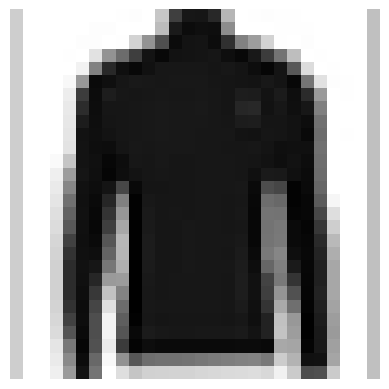

1/1 [==============================] - 0s 13ms/step
Predicted class: 2
Confidence: 0.92308134


In [36]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Load and preprocess the image
image_path = "phototest.jpg"
image = Image.open(image_path).convert('L')  # Convert to grayscale
image = image.resize((28, 28))  # Resize to match the input size of the model
image = np.array(image)  # Convert to numpy array
image = image.reshape((1, 28, 28, 1)).astype('float32') / 255  # Reshape and normalize

# Display the image
plt.imshow(image.reshape(28, 28), cmap='gray')
plt.axis('off')
plt.show()

# Make predictions
predictions = model.predict(image)

# Interpret the results
predicted_class = np.argmax(predictions)
confidence = np.max(predictions)

# Print the predicted class and confidence
print("Predicted class:", predicted_class)
print("Confidence:", confidence)
